In [1]:
#histograms, boxplots, scatterplots

In [2]:
import numpy as np
import pandas as pd
import cufflinks as cf
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio

In [3]:
import sklearn 
from sklearn.preprocessing import StandardScaler

In [4]:
# generate a line chart from a data frame
address = r"C:\Users\despi\OneDrive\Desktop\Python for DS and ML Part 1 - older version\data\mtcars.csv"
cars = pd.read_csv(address)
cars.columns = ['car_names', 'mpg',	'cyl',	'disp',	'hp',	'drat',	'wt',	'qsec',	'vs',	'am',	'gear',	'carb']

In [5]:
mpg = cars.mpg



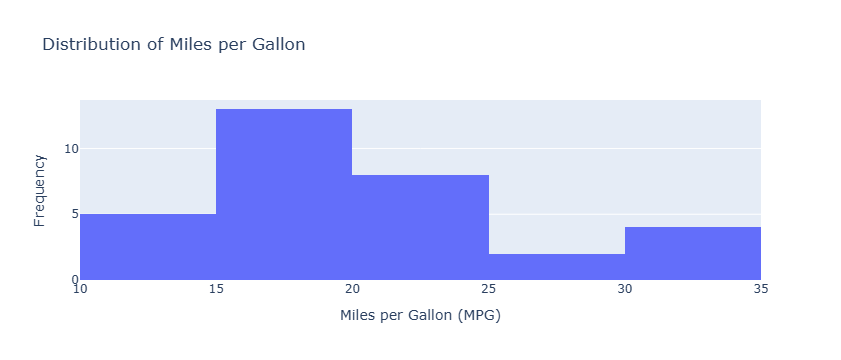

In [9]:
# Create histogram
fig = go.Figure(
    data=[go.Histogram(
        x=cars['mpg'],
        nbinsx=10
    )]
)

# Add titles
fig.update_layout(
    title="Distribution of Miles per Gallon",
    xaxis_title="Miles per Gallon (MPG)",
    yaxis_title="Frequency"
)

# Display histogram
fig.show()

In [11]:
cars_subset = cars[['mpg','disp','hp']]

cars_data_std = StandardScaler().fit_transform(cars_subset)

cars_select = pd.DataFrame(cars_data_std)
cars_select.columns = ['mpg','disp','hp']

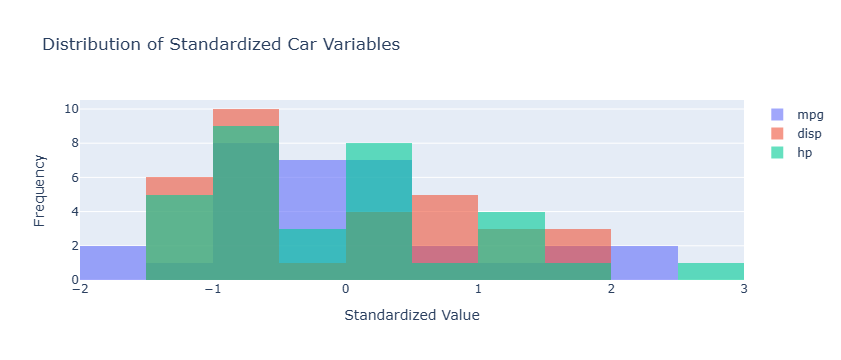

In [12]:
# Create histograms
fig = go.Figure()

for col in cars_select.columns:
    fig.add_trace(
        go.Histogram(
            x=cars_select[col],
            name=col,
            opacity=0.6,
            nbinsx=10
        )
    )

# Customize layout
fig.update_layout(
    title="Distribution of Standardized Car Variables",
    xaxis_title="Standardized Value",
    yaxis_title="Frequency",
    barmode="overlay"
)

fig.show()

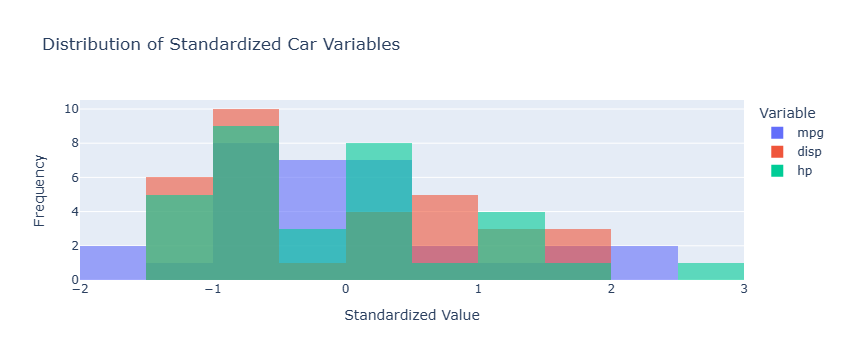

In [13]:
#using plotly express
fig = px.histogram(
    cars_select,
    x=['mpg', 'disp', 'hp'],
    nbins=10,
    barmode='overlay',
    opacity=0.6,
    title="Distribution of Standardized Car Variables"
)

fig.update_layout(
    xaxis_title="Standardized Value",
    yaxis_title="Frequency",
    legend_title="Variable"
)

fig.show()

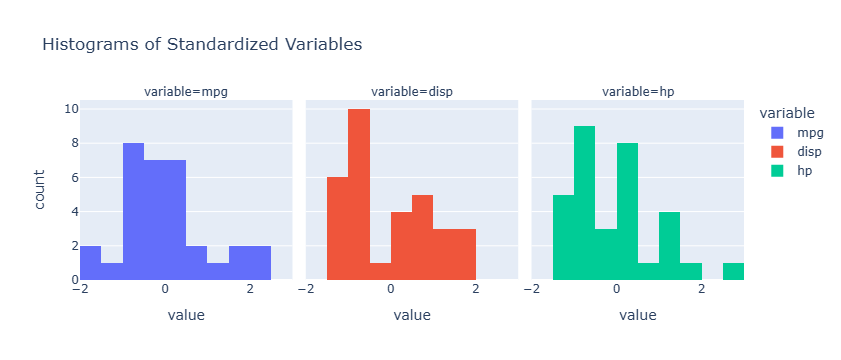

In [14]:
#display 3 separate histograms
fig = px.histogram(
    cars_select,
    x=['mpg', 'disp', 'hp'],
    facet_col='variable',
    nbins=10,
    title="Histograms of Standardized Variables"
)

fig.show()

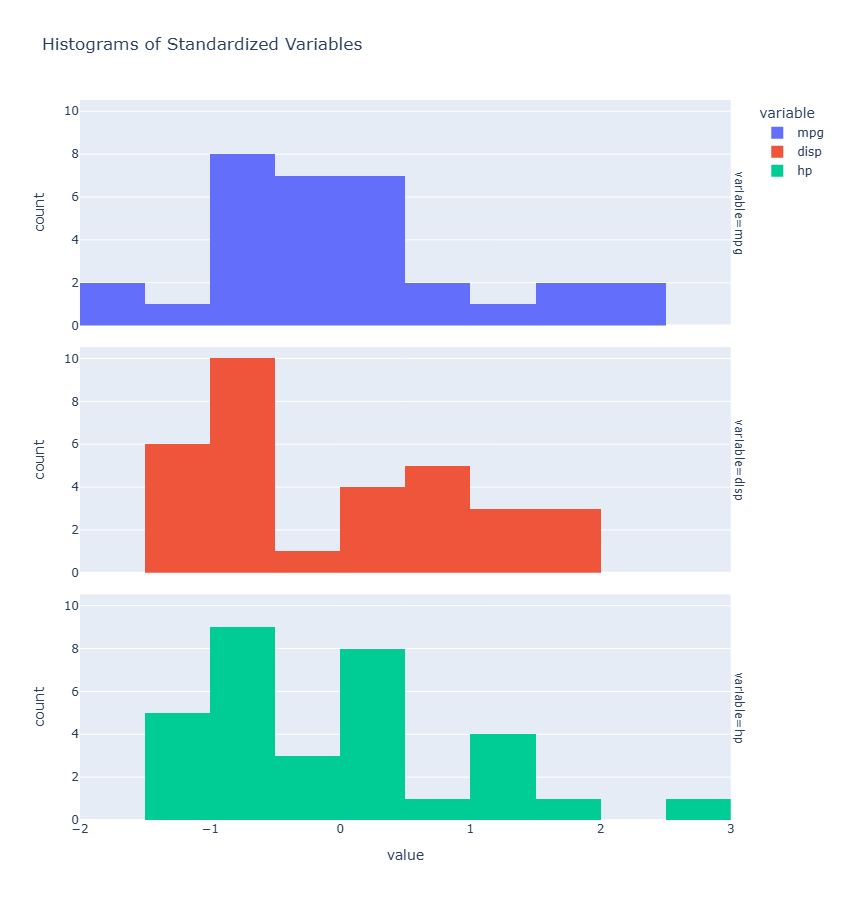

In [15]:
fig = px.histogram(
    cars_select,
    x=['mpg', 'disp', 'hp'],
    facet_row='variable',
    nbins=10,
    title="Histograms of Standardized Variables"
)

fig.update_layout(
    height=900,
    width=700
)

fig.show()

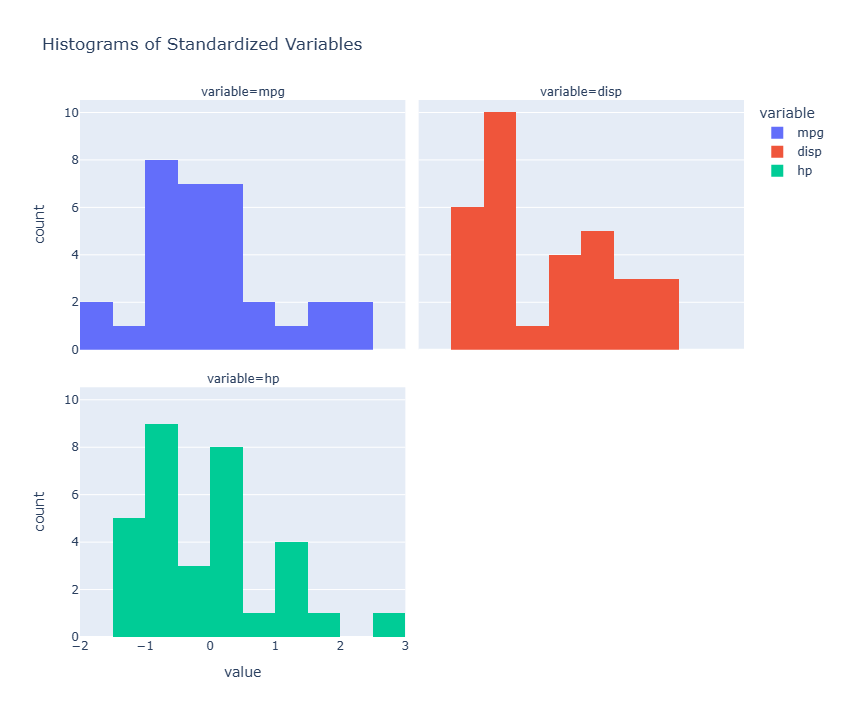

In [16]:
fig = px.histogram(
    cars_select,
    x=['mpg', 'disp', 'hp'],
    facet_col='variable',
    facet_col_wrap=2,
    nbins=10,
    title="Histograms of Standardized Variables"
)

fig.update_layout(
    height=700,
    width=900
)

fig.show()

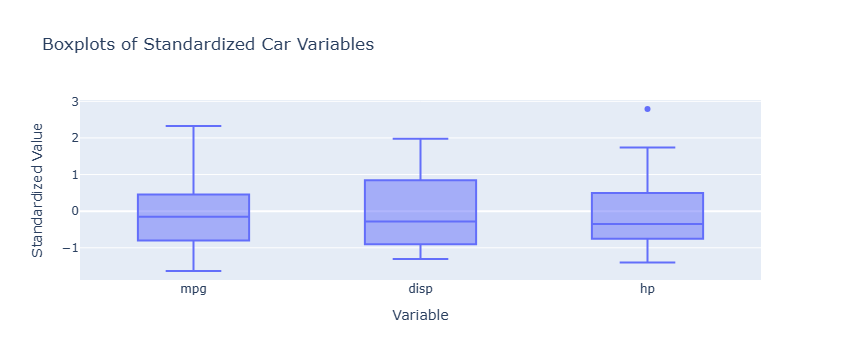

In [17]:
#create a boxplot
import plotly.express as px

fig = px.box(
    cars_select,
    y=['mpg', 'disp', 'hp'],
    title="Boxplots of Standardized Car Variables",
    points="outliers"
)

fig.update_layout(
    xaxis_title="Variable",
    yaxis_title="Standardized Value"
)

fig.show()

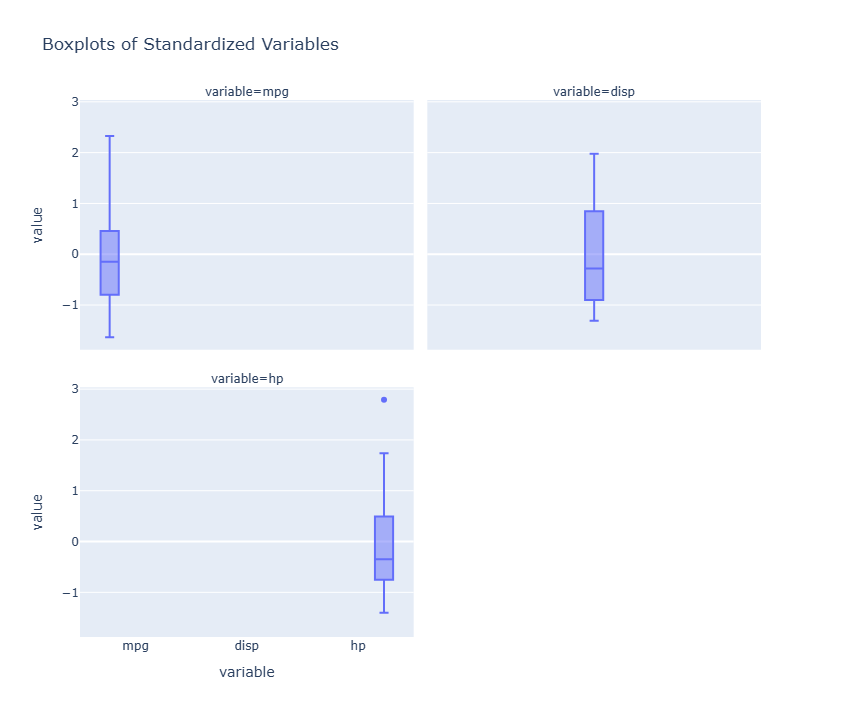

In [18]:
#same layout as for the histograms
fig = px.box(
    cars_select,
    y=['mpg', 'disp', 'hp'],
    facet_col='variable',
    facet_col_wrap=2,
    points="outliers",
    title="Boxplots of Standardized Variables"
)

fig.update_layout(
    height=700,
    width=900
)

fig.show()

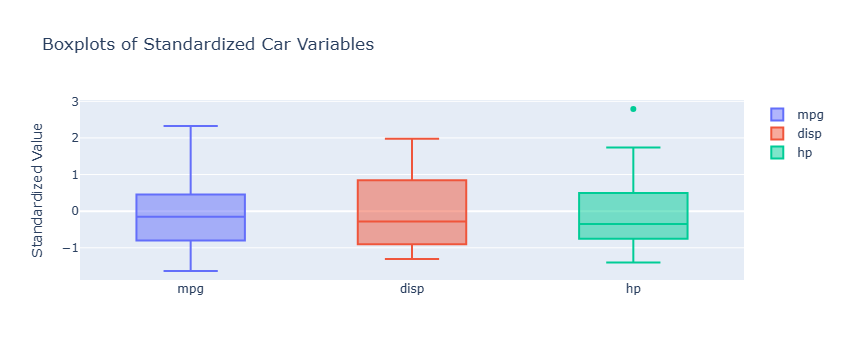

In [19]:
#using plotly graph objects
import plotly.graph_objects as go

fig = go.Figure()

for col in cars_select.columns:
    fig.add_trace(
        go.Box(
            y=cars_select[col],
            name=col,
            boxpoints="outliers"
        )
    )

fig.update_layout(
    title="Boxplots of Standardized Car Variables",
    yaxis_title="Standardized Value"
)

fig.show()

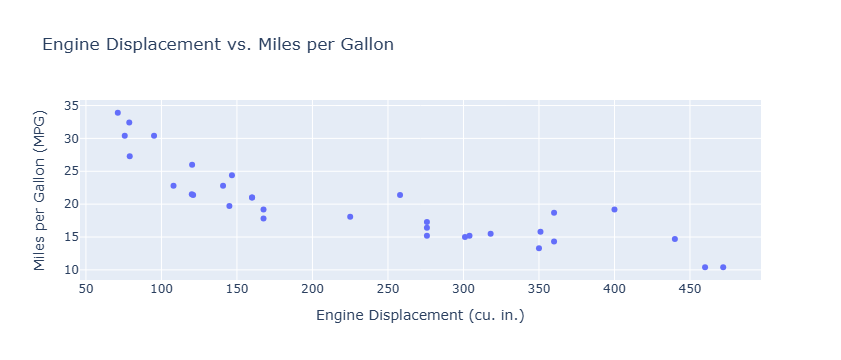

In [20]:
#create a scatterplot
import plotly.express as px

fig = px.scatter(
    cars,
    x='disp',
    y='mpg',
    title="Engine Displacement vs. Miles per Gallon",
    labels={
        'disp': 'Engine Displacement (cu. in.)',
        'mpg': 'Miles per Gallon (MPG)'
    }
)

fig.show()

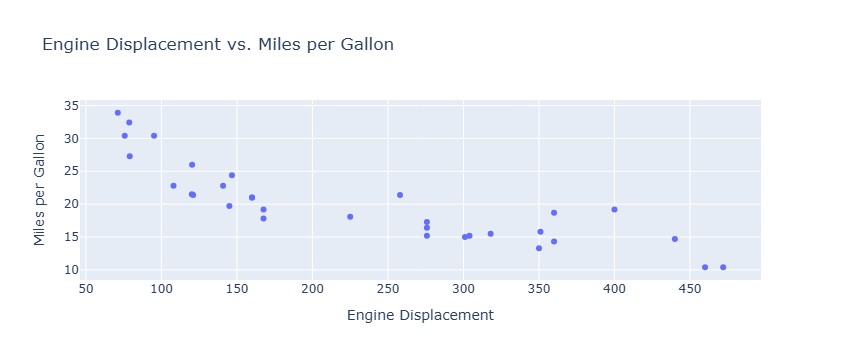

In [21]:
#using plotly graph objects
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=cars['disp'],
        y=cars['mpg'],
        mode='markers',
        name='Cars'
    )
)

fig.update_layout(
    title="Engine Displacement vs. Miles per Gallon",
    xaxis_title="Engine Displacement",
    yaxis_title="Miles per Gallon"
)

fig.show()

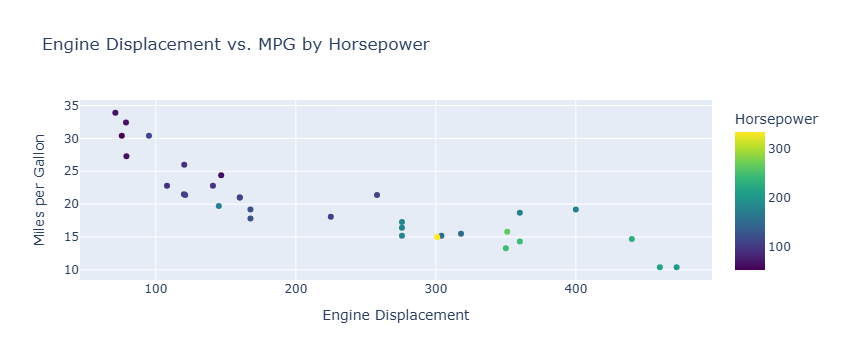

In [22]:
#overlay hp
import plotly.express as px

fig = px.scatter(
    cars,
    x='disp',
    y='mpg',
    color='hp',
    hover_name='car_names',
    title="Engine Displacement vs. MPG by Horsepower",
    labels={
        'disp': 'Engine Displacement',
        'mpg': 'Miles per Gallon',
        'hp': 'Horsepower'
    },
    color_continuous_scale='Viridis'
)

fig.show()

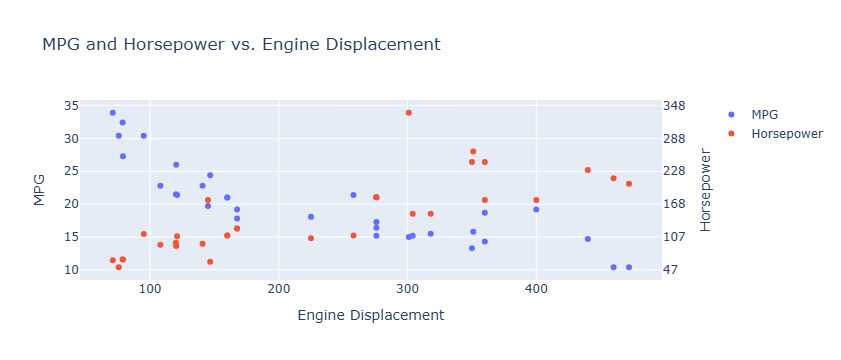

In [23]:
#overlay hp as a second series
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(
    go.Scatter(
        x=cars['disp'],
        y=cars['mpg'],
        mode='markers',
        name='MPG'
    ),
    secondary_y=False
)

fig.add_trace(
    go.Scatter(
        x=cars['disp'],
        y=cars['hp'],
        mode='markers',
        name='Horsepower'
    ),
    secondary_y=True
)

fig.update_layout(
    title="MPG and Horsepower vs. Engine Displacement",
    xaxis_title="Engine Displacement"
)

fig.update_yaxes(title_text="MPG", secondary_y=False)
fig.update_yaxes(title_text="Horsepower", secondary_y=True)

fig.show()

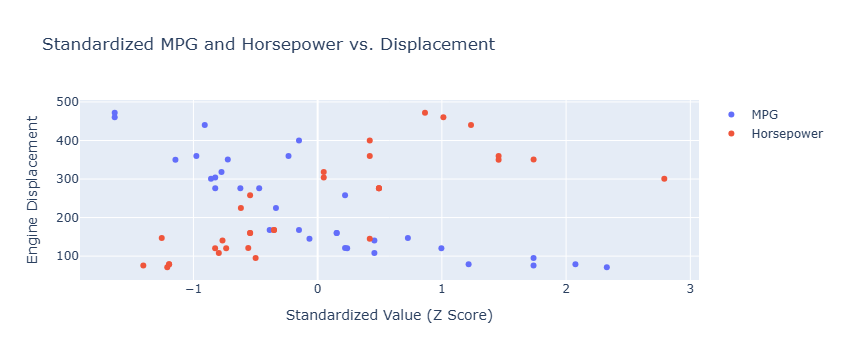

In [25]:
#plot displacement on the y-axis
import pandas as pd
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler

# Standardize MPG and horsepower
scaler = StandardScaler()

cars_std = cars.copy()
cars_std[['mpg', 'hp']] = scaler.fit_transform(cars[['mpg', 'hp']])

# Create scatterplot
fig = go.Figure()

# Standardized MPG vs Displacement
fig.add_trace(
    go.Scatter(
        x=cars_std['mpg'],
        y=cars_std['disp'],
        mode='markers',
        name='MPG'
    )
)

# Standardized Horsepower vs Displacement
fig.add_trace(
    go.Scatter(
        x=cars_std['hp'],
        y=cars_std['disp'],
        mode='markers',
        name='Horsepower'
    )
)

# Customize layout
fig.update_layout(
    title="Standardized MPG and Horsepower vs. Displacement",
    xaxis_title="Standardized Value (Z Score)",
    yaxis_title="Engine Displacement",
    hovermode="closest"
)

fig.show()